# Chocolate Flavor Intelligence: mainstream brands in India

**Cadbury · Amul · Nestle · Hershey's · Ferrero Rocher · Snickers**

Analyze flavor assortment, normalized retail pricing and customer rating evidence using real public retailer-index observations. This is not national market share or a live synchronized price panel. Read the [data dictionary](../docs/DATA_DICTIONARY.md) for capture dates and limitations.

In [1]:
from pathlib import Path
import os, sys, sqlite3, json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name == 'notebooks': ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.run import main
main()
conn=sqlite3.connect('data/chocolate.sqlite')

Products: 161 ; priced: 155


    validation               model   n  groups       mae        r2
family_grouped       global_median 155      72 46.037666 -0.043388
family_grouped brand_format_median 155      72 35.854692  0.528267
family_grouped  brand_format_ridge 155      72 39.958401  0.230035
family_grouped          full_ridge 155      72 45.081605  0.106567
  unseen_brand       global_median 155       6 49.227925 -0.097253
  unseen_brand brand_format_median 155       6 49.227925 -0.097253
  unseen_brand  brand_format_ridge 155       6 48.972704 -0.067971
  unseen_brand          full_ridge 155       6 50.307433 -0.118703
recent_sources       global_median 125      60 31.055360 -0.013053
recent_sources brand_format_median 125      60 30.437361 -0.054841
recent_sources  brand_format_ridge 125      60 32.035060 -0.014337
recent_sources          full_ridge 125      60 35.258628 -0.239146
 exclude_gifts       global_median 137      66 38.835208 -0.028542
 exclude_gifts brand_format_median 137      66 33.149125  0.30

## 1. Inspect provenance and scope

Retrieval date differs from crawl age. Seven category pages cover six brand groups. Raw records remain available alongside exclusions. Product-card IDs are snapshot-specific and are not stable manufacturer SKUs.

In [2]:
display(pd.read_csv('reports/tables/07_source_quality.csv'))
display(pd.read_csv('reports/tables/exclusions.csv'))
display(pd.read_sql_query("SELECT brand,COUNT(*) AS listings,COUNT(rating) AS rated FROM products GROUP BY brand",conn))

,source_id,brand,crawl_age_days_approx,retained_listings,missing_prices,missing_ratings,missing_weights
0,silk,Cadbury,90,24,2,3,0
1,ferrero,Ferrero Rocher,60,8,0,3,0
2,hershey,Hershey's,30,20,0,1,0
3,snickers,Snickers,30,15,0,2,0
4,dairymilk,Cadbury,5,18,2,0,0
5,nestle,Nestle,2,39,2,2,0
6,amul,Amul,0,37,0,2,0


,observation_id,title,reason
0,amul_014,Amul Dark Compound Slab - Dco-18,baking ingredient or non-chocolate candy
1,amul_022,Amul White Compound Slab - Wco-20,baking ingredient or non-chocolate candy
2,amul_040,Amul Dark Chocolate Slab - Dch-47,baking ingredient or non-chocolate candy
3,nestle_005,Nestle Polo Mint,baking ingredient or non-chocolate candy
4,silk_020,Cadbury Dairy Milk Silk Dairy Milk Silk Chocol...,duplicate normalized title and total pack weig...
5,hershey_001,Hershey's Kisses Milk Chocolate,incomplete search preview without a product card


,brand,listings,rated
0,Amul,37,35
1,Cadbury,42,39
2,Ferrero Rocher,8,5
3,Hershey's,20,19
4,Nestle,39,37
5,Snickers,15,13


## 2. Pack normalization changes the comparison

`3x51g` means 153g total; `111g (15x7.4g)` already states total mass. Price comparisons use total grams, not one unit's mass. The SQL view excludes missing prices without inventing targets. Formats such as wafers and gift packs are explicitly separated.

,pack,total_g
0,3x51 g - (Multipack),153.0
1,16 g - (Pack of 9),144.0
2,111 g - (15x7.4 g),111.0


,brand,priced_listings,median_inr_per_100g,min_price,max_price
0,Amul,37,120.000000,40.000000,146.666667
1,Cadbury,38,139.744444,62.500000,365.357143
2,Ferrero Rocher,8,328.500000,232.760000,554.444444
3,Hershey's,20,162.134921,84.745763,203.571429
4,Nestle,37,100.000000,49.242424,190.476190
5,Snickers,15,129.545455,79.444444,245.115090


,title,total_weight_g,price_inr,price_per_100g
0,Amul Dark Chocolate,150.0,180.0,120.0
1,"Amul Fruit N Nut, Dark Chocolate- 55% Rich In ...",150.0,180.0,120.0
2,Amul Tropical Orange Dark Chocolate,150.0,180.0,120.0


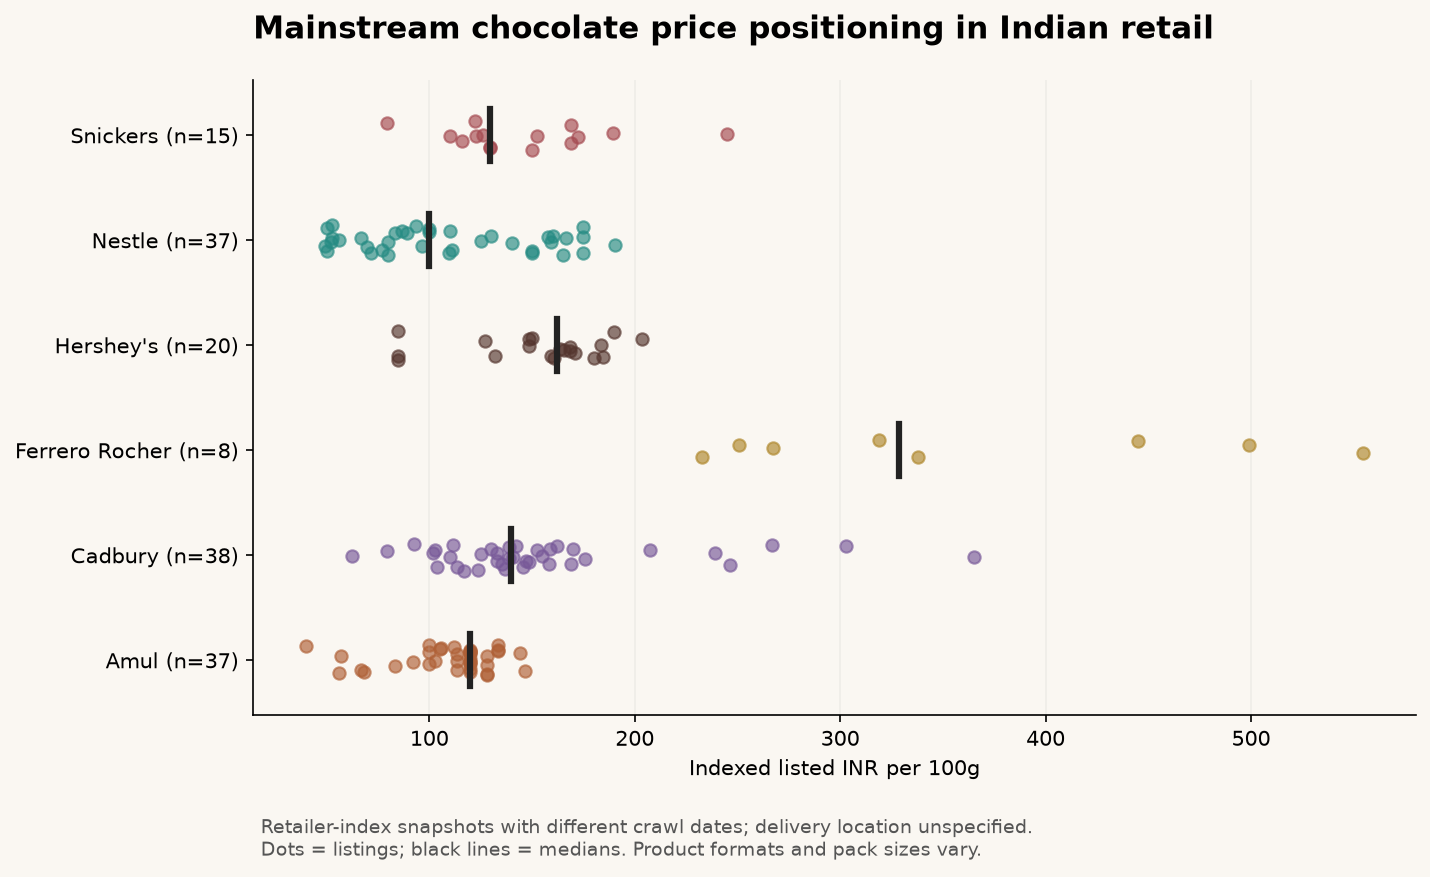

In [3]:
from src.features import weight
display(pd.DataFrame({'pack':['3x51 g - (Multipack)','16 g - (Pack of 9)','111 g - (15x7.4 g)'],
                      'total_g':[weight(x) for x in ['3x51 g - (Multipack)','16 g - (Pack of 9)','111 g - (15x7.4 g)']]}))
display(pd.read_csv('reports/tables/brand_medians.csv'))
display(pd.read_csv('reports/tables/amul_matched_comparison.csv'))
display(Image(filename='reports/figures/price_positioning.png'))

## 3. SQL and interpretable flavor features

Tags describe marketed title cues, not a full ingredient inventory. Categories overlap. Listings can repeat recipes in multiple pack sizes; observed counts are not popularity or demand. The query below compares a flavor with its own brand-format benchmark, which helps expose confounding but does not establish causality.

WITH benchmark AS (
 SELECT brand,format,AVG(price_per_100g) mean_price FROM priced_products GROUP BY brand,format
)
SELECT p.brand,p.format,f.flavor,COUNT(*) n,
 ROUND(AVG(p.price_per_100g),2) AS mean_inr_per_100g,
 ROUND(AVG(p.price_per_100g-b.mean_price),2) AS difference_from_brand_format_mean
FROM priced_products p JOIN product_flavors f USING(observation_id)
JOIN benchmark b ON p.brand=b.brand AND p.format=b.format
GROUP BY p.brand,p.format,f.flavor ORDER BY p.brand,p.format,n DESC;



,brand,format,flavor,n,mean_inr_per_100g,difference_from_brand_format_mean
0,Amul,bar_other,no_named_inclusion,21,118.52,3.43
1,Amul,bar_other,fruit,5,120.00,4.91
2,Amul,bar_other,nuts,4,114.29,-0.81
3,Amul,bar_other,spice_tea,1,40.00,-75.09
4,Amul,bar_other,coffee,1,120.00,4.91
5,Amul,bites_tubes,no_named_inclusion,4,81.05,-4.79
6,Amul,bites_tubes,nuts,1,105.00,19.16
7,Amul,gift_assortment,no_named_inclusion,1,102.86,0.00
8,Amul,wafer,no_named_inclusion,1,66.67,0.00
9,Cadbury,bar_other,no_named_inclusion,10,130.08,-17.64


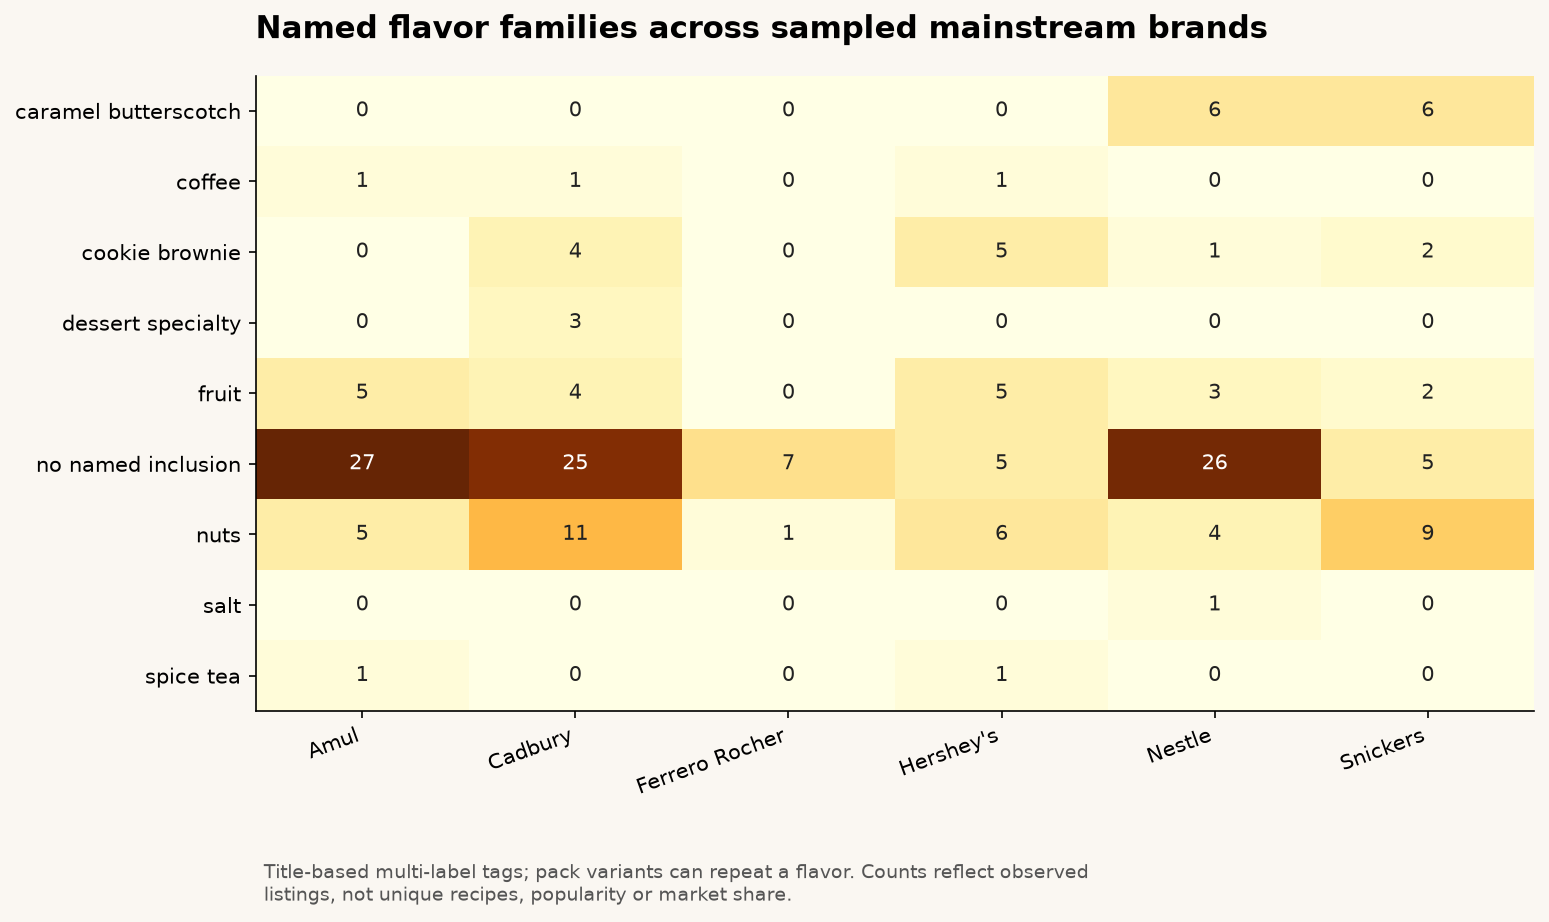

In [4]:
query=Path('sql/03_brand_format_flavors.sql').read_text()
print(query)
display(pd.read_sql_query(query,conn).head(20))
display(Image(filename='reports/figures/flavor_assortment.png'))

## 4. Consumer evidence: aggregate ratings

Only displayed average stars and counts were captured. Ratings may be pooled across packs, so counts are not summed as unique reviews. No individual review text or sentiment analysis is claimed.

Descriptive shrinkage uses an equal-weight brand mean as prior and pseudo-counts 20/100/500. This is not a calibrated posterior or a population preference estimate. A high average supported by very few ratings is a question for further research.

,brand,listings,rated_listings,rated_below_100,unweighted_mean_displayed_stars
0,Amul,37,35,2,4.186
1,Cadbury,42,39,7,4.154
2,Ferrero Rocher,8,5,0,4.160
3,Hershey's,20,19,4,4.042
4,Nestle,39,37,11,4.200
5,Snickers,15,13,4,4.154


,observation_id,brand,title,pack_label,rating,rating_count,smoothed_score,within_brand_rank
0,amul_003,Amul,Amul Almondo - Chocolate Coated Almonds,200 g,4.4,2211,4.390728,1
1,amul_006,Amul,"Amul Chocolate - Dark, Minis, Gable Top",100 g,4.4,598,4.369300,2
35,silk_001,Cadbury,Cadbury Dairy Milk Silk Mousse Chocolate Bar,3x110 g - (Multipack),4.3,2347,4.294027,1
36,silk_023,Cadbury,Cadbury Dairy Milk Silk Valentines Heart Blush...,150 g,4.3,404,4.271001,2
74,ferrero_002,Ferrero Rocher,Ferrero Rocher Gift Pack,50 g - (4 pcs),4.3,2047,4.293479,1
75,ferrero_004,Ferrero Rocher,Ferrero Rocher Moments Chocolate,185.6 g - (32 pcs),4.2,469,4.192970,2
79,hershey_003,Hershey's,Hershey's Cookies 'N' Creme Choco Tubes,23.6 g,4.3,456,4.253616,1
80,hershey_002,Hershey's,Hershey's Creamy Milk Choco Tubes,23.6 g,4.3,381,4.246384,2
98,nestle_006,Nestle,Nestle Munch Nuts - Chocolate Coated Crunchy W...,16 g - (Pack of 9),4.4,285,4.348052,1
99,nestle_004,Nestle,Nestle Munch Max Chocolate Coated Wafer Bar,115.5 g - (3x38.5 g),4.3,10198,4.299029,2


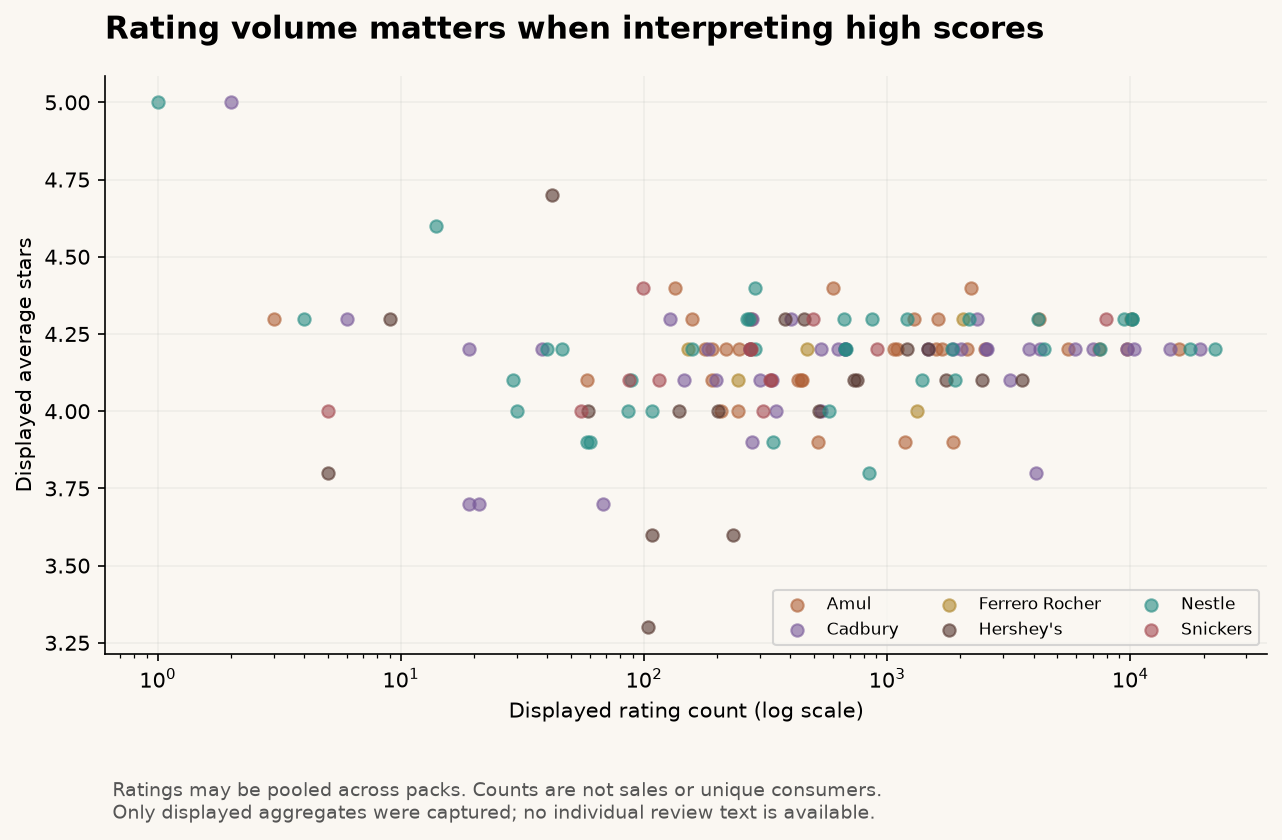

In [5]:
display(pd.read_csv('reports/tables/06_rating_evidence.csv'))
display(pd.read_csv('reports/tables/04_rating_shrinkage.csv').groupby('brand',sort=False).head(2))
display(Image(filename='reports/figures/rating_evidence.png'))

## 5. Predictive experiment and sensitivity

The target is listed INR/100g. Compare global and brand/format median baselines with ridge models. The full model adds mass, sparse cocoa percentage and flavor flags. Encoding, imputation and scaling fit inside each training fold; alpha=10 is fixed without tuning on test predictions.

Family groups combine brand, subbrand, format and flavor tags. Similar packs stay together. Leave-one-brand-out measures transfer. Recent-source-only and no-gift evaluations expose sensitivity to source age and merchandising mix. Cluster-bootstrap intervals resample fixed held-out errors, not the entire fitting procedure.

,validation,model,n,groups,mae,r2
0,family_grouped,global_median,155,72,46.037666,-0.043388
1,family_grouped,brand_format_median,155,72,35.854692,0.528267
2,family_grouped,brand_format_ridge,155,72,39.958401,0.230035
3,family_grouped,full_ridge,155,72,45.081605,0.106567
4,unseen_brand,global_median,155,6,49.227925,-0.097253
5,unseen_brand,brand_format_median,155,6,49.227925,-0.097253
6,unseen_brand,brand_format_ridge,155,6,48.972704,-0.067971
7,unseen_brand,full_ridge,155,6,50.307433,-0.118703
8,recent_sources,global_median,125,60,31.055360,-0.013053
9,recent_sources,brand_format_median,125,60,30.437361,-0.054841


,validation,mae_improvement_full_vs_baseline,lower95,upper95
0,family_grouped,-9.226912,-17.800777,-0.870170
1,unseen_brand,-1.079508,-4.609040,3.843498
2,recent_sources,-4.821267,-11.551559,2.602380
3,exclude_gifts,-4.675922,-13.683468,5.353493


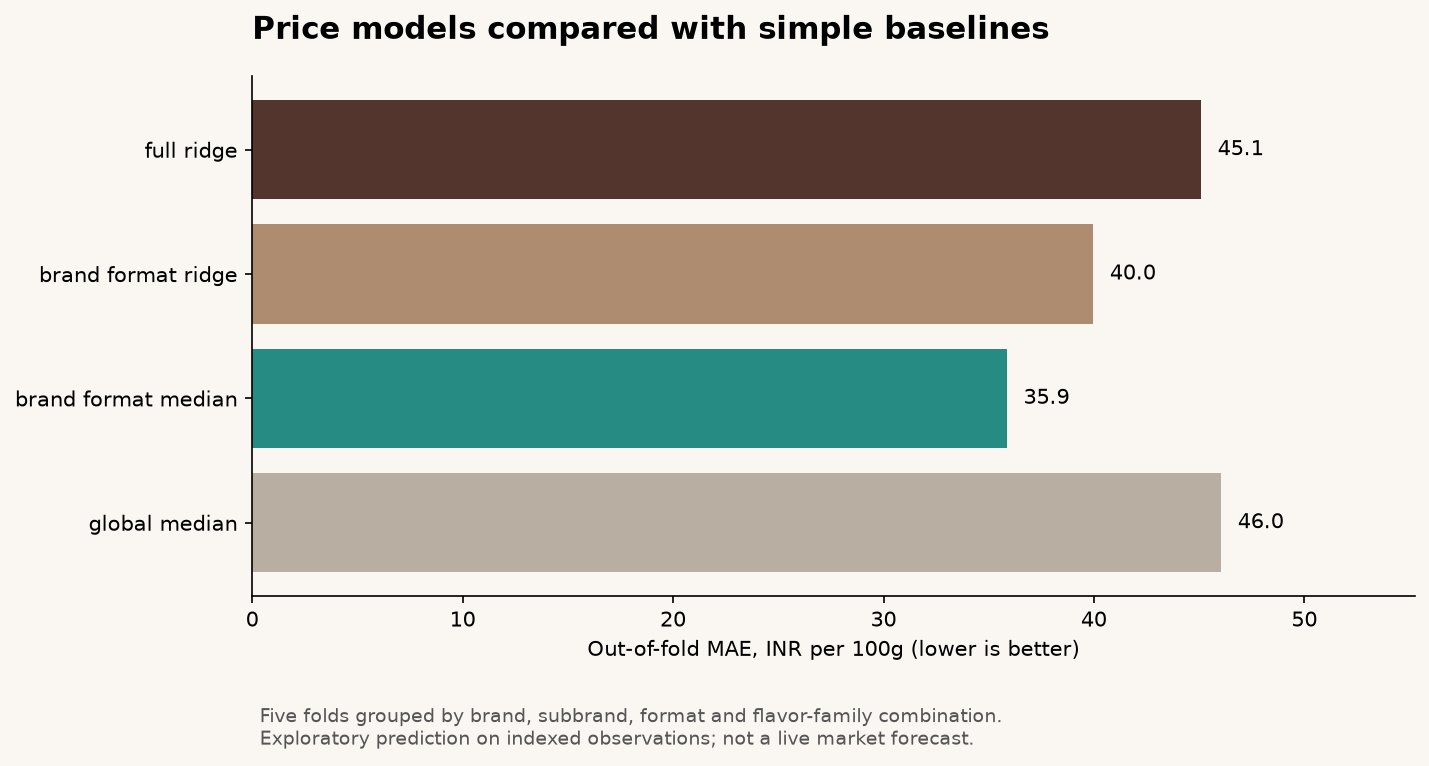

In [6]:
display(pd.read_csv('reports/tables/model_metrics.csv'))
display(pd.DataFrame(json.loads(Path('reports/model_uncertainty.json').read_text())))
display(Image(filename='reports/figures/model_validation.png'))

## 6. Business interpretation

The sampled 150g Amul plain dark, orange and fruit-and-nut products share a listed INR180 price. This is a useful matched comparison, not a national pricing rule. Brand and format structure matter; a richer model must earn its complexity against baselines.

Before a pricing or product-launch decision, collect synchronized prices for one postcode, add other retailers, verify ingredients and obtain independent consumer/sales outcomes. Read [the generated findings](../reports/FINDINGS.md) and [model card](../docs/MODEL_CARD.md).

**Exercises:** exclude listings with Notify Me; compare medians within format; audit source-age effects; change one flavor rule and review affected records. Treat exploratory model changes as sensitivity tests rather than selecting the best reported test score.

In [7]:
conn.close()
print('Offline analysis completed; reports and SQL tables are regenerated.')

Offline analysis completed; reports and SQL tables are regenerated.
